## Simple Bot

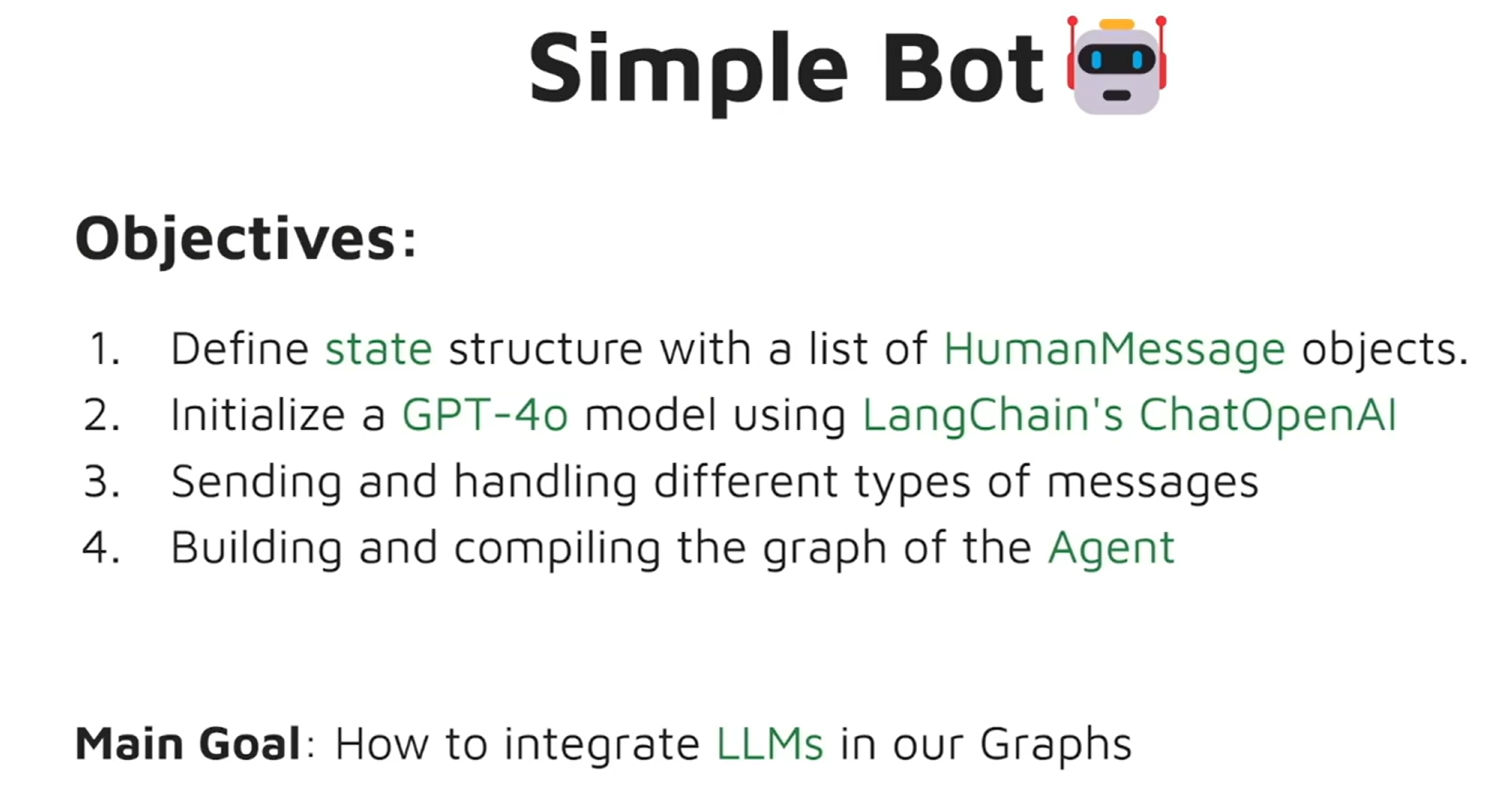

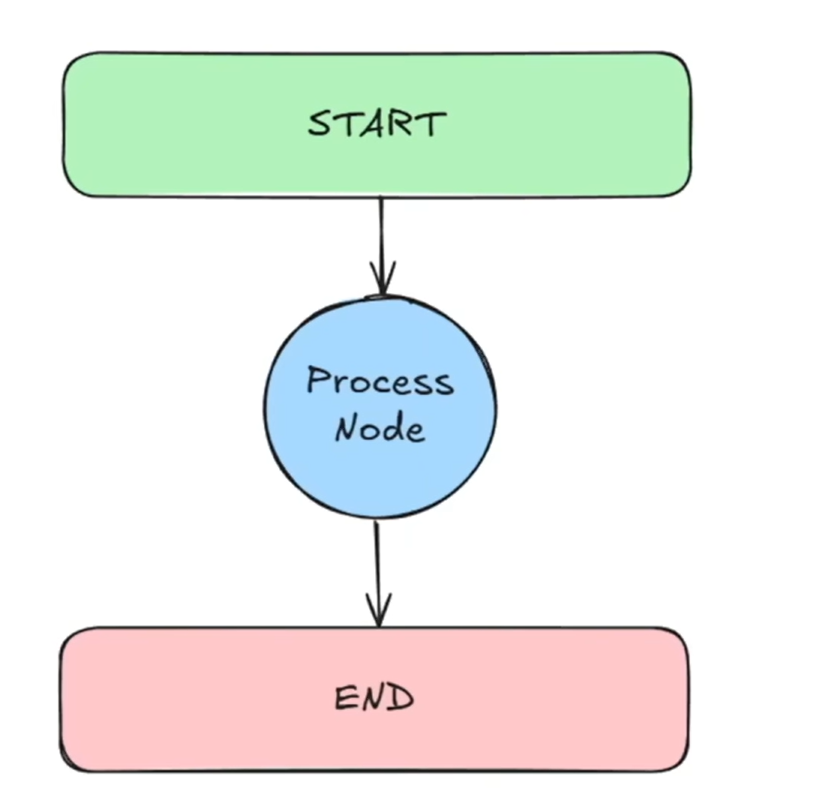

In [1]:
from typing import TypedDict
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [30]:
class AgentState(TypedDict):
    messages: list[HumanMessage]

In [31]:
llm = ChatOpenAI(model="gpt-5-nano")

In [32]:
def process(state: AgentState) -> AgentState:
    response = llm.invoke(state["messages"])
    print(state["messages"])
    print(f"{response.content}")
    return state

In [33]:
graph = StateGraph(AgentState)
graph.add_node("process", process)
graph.add_edge(START, "process")
graph.add_edge("process", END)
agent = graph.compile()

In [34]:
user_input = input("Enter: ")
while user_input != "exit":
    agent.invoke({"messages": [HumanMessage(content = user_input)]})
    user_input = input("Enter: ")

[HumanMessage(content='hi', additional_kwargs={}, response_metadata={})]
Hi there! How can I help today? Tell me what you’d like to do—answer a question, get help with writing or coding, plan something, or just chat. What would you like to talk about?
